# E218 · Does temporal prediction learn actual dynamics?

We reuse E217’s frozen DINO and capture-disjoint BDD clips. The registered offsets span approximately 0.53–4.27 seconds. The shuffled control offsets targets by half the time grid within the same clip and lag, preserving target marginals and scene identity. All models are evaluated on true ordered pairs. Mean reversion fits one scalar shrinkage and target mean per lag on training clips. Identical residual heads are fitted on aligned and shuffled pairs, with epoch and shrinkage selected independently on development clips.

The local forecaster predicts each 14×14 ViT patch token projected to 64 dimensions. It sees the current token, the surrounding 3×3 average, and the change from eight frames earlier. Large-motion scores use the upper development quartile of grayscale pixel change after estimated translation and brightness correction. This proxy also responds to parallax and camera motion. It is used for stratified evaluation only.

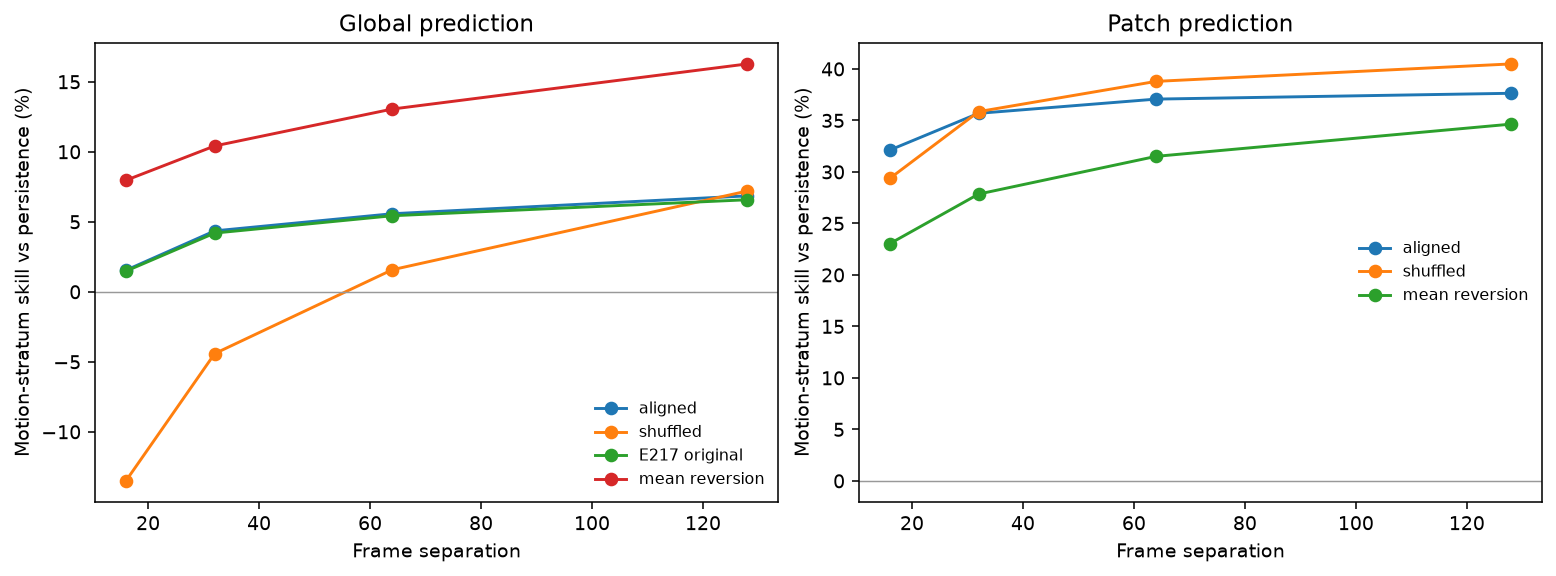

| Surface | Predictor | Overall skill | High-motion skill |
| --- | --- | --- | --- |
| global | aligned | +6.73% | +4.81% |
| global | shuffled | +0.34% | -1.36% |
| global | E217 original | +6.68% | +4.63% |
| global | mean reversion | +13.58% | +12.34% |
| patch | aligned | +32.74% | +35.87% |
| patch | shuffled | +31.20% | +36.61% |
| patch | mean reversion | +24.23% | +29.75% |

| Surface | Contrast | Overall difference and clip interval | High-motion difference and clip interval |
| --- | --- | --- | --- |
| global | aligned minus shuffled | +6.39% [+4.34%, +9.07%] | +6.17% [+4.29%, +8.99%] |
| global | aligned minus mean | -6.85% [-8.55%, -4.88%] | -7.53% [-9.33%, -5.49%] |
| patch | aligned minus shuffled | +1.54% [+0.54%, +2.78%] | -0.74% [-1.28%, -0.14%] |
| patch | aligned minus mean | +8.51% [+7.86%, +9.19%] | +6.12% [+5.21%, +6.87%] |

## Downstream transfer

Three paired seeds, 128 updates per arm. All arms use the same SimSiam inputs, data order, and augmentation seeds. Matched aligned and shuffled arms keep their pair treatment during transfer, with identical target-frame multisets at each lag. Fitted temporal heads stay frozen. Auxiliary gradients are calibrated on development clips. Labels enter only the held-out frozen-feature probes. The primary result is time-averaged balanced accuracy.

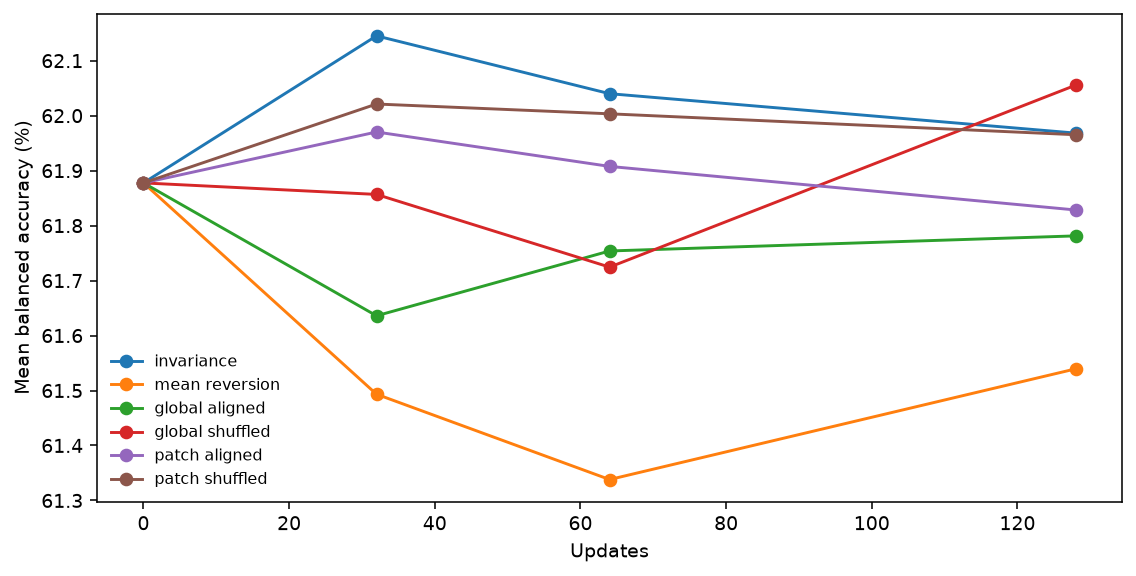

| Contrast | Probe | Mean difference (pp) | Paired seeds (pp) |
| --- | --- | --- | --- |
| global aligned minus global shuffled | semantic | -0.11 | -0.18, -0.08, -0.08 |
| global aligned minus global shuffled | scene linear | +0.10 | -0.17, +0.12, +0.34 |
| global aligned minus global shuffled | scene kNN | +0.04 | +0.14, +0.33, -0.35 |
| global aligned minus global shuffled | weather linear | -0.15 | -0.42, -0.08, +0.05 |
| global aligned minus global shuffled | lighting linear | -0.43 | -0.51, -0.42, -0.35 |
| global aligned minus global shuffled | traffic light linear | -0.07 | +0.00, -0.22, -0.00 |
| global aligned minus global shuffled | pedestrian linear | -0.01 | +0.18, +0.22, -0.42 |
| global aligned minus global shuffled | historical | +0.56 | +1.48, -0.30, +0.50 |
| global aligned minus mean reversion | semantic | +0.25 | +0.39, +0.31, +0.05 |
| global aligned minus mean reversion | scene linear | +0.36 | +0.54, +0.19, +0.36 |
| global aligned minus mean reversion | scene kNN | -0.28 | -0.54, -0.09, -0.23 |
| global aligned minus mean reversion | weather linear | +0.14 | +0.16, +0.18, +0.08 |
| global aligned minus mean reversion | lighting linear | +0.33 | +0.65, +0.29, +0.03 |
| global aligned minus mean reversion | traffic light linear | +0.02 | +0.27, +0.05, -0.25 |
| global aligned minus mean reversion | pedestrian linear | +0.41 | +0.36, +0.83, +0.05 |
| global aligned minus mean reversion | historical | +0.63 | +1.02, -0.10, +0.97 |
| patch aligned minus patch shuffled | semantic | -0.08 | -0.10, -0.23, +0.08 |
| patch aligned minus patch shuffled | scene linear | +0.20 | +0.97, -0.26, -0.11 |
| patch aligned minus patch shuffled | scene kNN | -0.07 | -0.05, -0.23, +0.07 |
| patch aligned minus patch shuffled | weather linear | +0.07 | -0.39, +0.12, +0.48 |
| patch aligned minus patch shuffled | lighting linear | -0.30 | -0.39, -0.57, +0.05 |
| patch aligned minus patch shuffled | traffic light linear | -0.19 | -0.26, -0.26, -0.07 |
| patch aligned minus patch shuffled | pedestrian linear | -0.19 | -0.41, -0.18, +0.02 |
| patch aligned minus patch shuffled | historical | -0.71 | -0.21, -0.89, -1.04 |
| patch aligned minus global aligned | semantic | +0.15 | +0.12, -0.08, +0.42 |
| patch aligned minus global aligned | scene linear | +0.19 | +0.65, -0.28, +0.19 |
| patch aligned minus global aligned | scene kNN | -0.03 | -0.07, -0.21, +0.19 |
| patch aligned minus global aligned | weather linear | -0.22 | -0.37, -0.12, -0.17 |
| patch aligned minus global aligned | lighting linear | -0.04 | -0.06, -0.14, +0.10 |
| patch aligned minus global aligned | traffic light linear | +0.79 | +0.51, +0.62, +1.23 |
| patch aligned minus global aligned | pedestrian linear | +0.05 | -0.11, -0.49, +0.75 |
| patch aligned minus global aligned | historical | -0.10 | -0.31, +0.42, -0.41 |
| patch aligned minus invariance | semantic | -0.13 | -0.40, -0.09, +0.11 |
| patch aligned minus invariance | scene linear | +0.19 | +0.15, +0.02, +0.40 |
| patch aligned minus invariance | scene kNN | -0.25 | -0.10, -0.16, -0.48 |
| patch aligned minus invariance | weather linear | -0.02 | -0.59, +0.50, +0.05 |
| patch aligned minus invariance | lighting linear | -0.35 | -0.30, -0.68, -0.05 |
| patch aligned minus invariance | traffic light linear | -0.30 | -0.64, -0.20, -0.05 |
| patch aligned minus invariance | pedestrian linear | -0.17 | -0.63, -0.09, +0.20 |
| patch aligned minus invariance | historical | -0.38 | -1.06, +0.02, -0.11 |